# House Prices (Ames)

* Data source: https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data
* Team:
* Team members:

**Dataset information**
| Column | Meaning |
|---|---|
| `SalePrice` | Price the house sold for (USD). This is what we predict. |
| `GrLivArea` | Living area above ground (sq ft) |
| `TotalBsmtSF`, `1stFlrSF`, `2ndFlrSF` | Basement area, 1st floor area, 2nd floor area (sq ft) |
| `LotArea`, `LotFrontage` | Size of the lot (sq ft), length of street touching the lot (ft) |
| `OverallQual`, `OverallCond` | Overall build quality and overall condition, scored 1 (very poor) up to 10 (very excellent) |
| `ExterQual`, `KitchenQual`, `BsmtQual`, ... | Quality ratings written as letters (`Po`, `Fa`, `TA`, `Gd`, `Ex`). Shown in section 1.4. |
| `Neighborhood` | Which part of Ames the house is in (25 areas) |
| `MSSubClass` | A code for the type of house (one-story, two-story, duplex...). Shown in section 1.4. |
| `SaleCondition` | How the sale happened (normal, foreclosure, new house not finished...) |
| `YearBuilt`, `YearRemodAdd`, `YrSold`, `MoSold` | Year built, year remodelled, year sold, month sold |
| `NA` in a column like `GarageType` | Usually means the house has no garage (or basement, pool...). Explained in section 1.2. |

## 0. SET UP

Download all necessary libraries

In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


Unzip dataset (skipped if there is no zip file and `train.csv` is already there)

In [2]:
import zipfile
from pathlib import Path

zip_path = Path("dataset/house.zip")
extract_dir = Path("dataset/unzip")
extract_dir.mkdir(parents=True, exist_ok=True)

if zip_path.exists():
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(extract_dir)

print("Files:", sorted(p.name for p in extract_dir.iterdir()))

Files: ['data_description.txt', 'sample_submission.csv', 'test.csv', 'train.csv']


Imports, settings, load the data.
> In this file, `NA` means feature absent, and `None` is a category value. They are not missing data

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 50)

raw = pd.read_csv("dataset/unzip/train.csv", keep_default_na=False, na_values=["NA"])
print("Rows, columns:", raw.shape)
raw.head(3)

Rows, columns: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,...,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,...,0,NaN,Attchd,"2,003.000",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,...,1,TA,Attchd,"1,976.000",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,"2,001.000",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


## 1. DATA CLEANING

**Goal**: find the problems in the raw data and decide what to do about each one.

**Rule**: we only use fixed rules (what a column means, what is obviously wrong).


### 1.1. Basic overview

In [4]:
df = raw.drop(columns="Id")

print("Rows, columns:", df.shape)
print()
print("Column types:")
print(df.dtypes.astype(str).value_counts().to_string())

Rows, columns: (1460, 80)

Column types:
str        43
int64      34
float64     3


* 1,460 houses and 80 columns (`Id` dropped). 43 are text, 34 are whole numbers, 3 have decimals.

In [5]:
look = ["SalePrice", "LotArea", "LotFrontage", "MasVnrArea", "MiscVal"]
df[look].describe().loc[["count", "mean", "50%", "75%", "max"]]

,SalePrice,LotArea,LotFrontage,MasVnrArea,MiscVal
count,"1,460.000","1,460.000","1,201.000","1,452.000","1,460.000"
mean,"180,921.196","10,516.828",70.050,103.685,43.489
50%,"163,000.000","9,478.500",69.000,0.000,0.000
75%,"214,000.000","11,601.500",80.000,166.000,0.000
max,"755,000.000","215,245.000",313.000,"1,600.000","15,500.000"


* `SalePrice`: the mean (180,921) is higher than the median (163,000), and the max (755,000) is far above the 75% mark (214,000). A few very expensive houses stretch the price to the right.
* Some columns have a max far away from it's 75%:
    * `LotArea` max 215,245 vs 75% = 11,601
    * `LotFrontage` max 313 vs 75% = 80
    * `MasVnrArea` max 1,600 vs 75% = 166
    * `MiscVal` max 15,500 vs 75% = 0
* `LotFrontage` has 1,201 values out of 1,460, so 259 are missing.

### 1.2. Missing values

Columns with NA: 19


,missing_count,missing_pct,meaning
PoolQC,1453,99.500,house doesn't have it
MiscFeature,1406,96.300,house doesn't have it
Alley,1369,93.800,house doesn't have it
Fence,1179,80.800,house doesn't have it
FireplaceQu,690,47.300,house doesn't have it
LotFrontage,259,17.700,really missing
GarageCond,81,5.500,house doesn't have it
GarageType,81,5.500,house doesn't have it
GarageYrBlt,81,5.500,house doesn't have it
GarageFinish,81,5.500,house doesn't have it


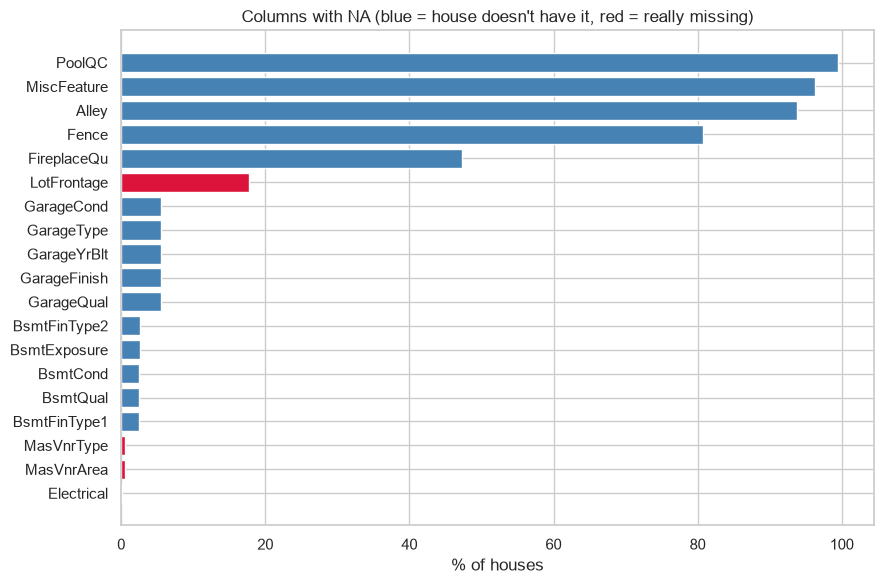

In [6]:
# Columns where NA means "the house doesn't have it"
absent_cat_cols = ["Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
                   "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                   "PoolQC", "Fence", "MiscFeature"]
absent_num_cols = ["GarageYrBlt"]       # NA = no garage

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": (missing / len(df) * 100).round(1),
})
missing_report["meaning"] = np.where(missing_report.index.isin(absent_cat_cols + absent_num_cols),
                                     "house doesn't have it", "really missing")
print("Columns with NA:", len(missing_report))
display(missing_report)

colors = missing_report["meaning"].map({"house doesn't have it": "steelblue", "really missing": "crimson"})
plt.figure(figsize=(9, 6))
plt.barh(missing_report.index, missing_report["missing_pct"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("% of houses")
plt.title("Columns with NA (blue = house doesn't have it, red = really missing)")
plt.tight_layout()
plt.show()

- 19 columns have NA. In 15 of them (blue) NA means the house doesn't have it: `PoolQC` 99.5%, `MiscFeature` 96.3%, `Alley` 93.8%, `Fence` 80.8%, `FireplaceQu` 47.3%, the five garage columns 5.5%, the basement columns 2.5-2.6%.
- Only 4 columns are really missing (red): `LotFrontage` 259 houses (17.7%), `MasVnrType` 8, `MasVnrArea` 8 (the same 8 houses) and `Electrical` 1.

Is `NA` really "the house doesn't have it"? Here are three houses with `NA` in the garage columns, and three with `NA` in the basement columns:

In [7]:
print("Houses with NA in GarageType:")
display(df.loc[df["GarageType"].isna(), ["GarageType", "GarageFinish", "GarageCars", "GarageArea"]].head(3))
print("Houses with NA in BsmtQual:")
display(df.loc[df["BsmtQual"].isna(), ["BsmtQual", "BsmtFinType1", "TotalBsmtSF"]].head(3))

Houses with NA in GarageType:


,GarageType,GarageFinish,GarageCars,GarageArea
39,NaN,NaN,0,0
48,NaN,NaN,0,0
78,NaN,NaN,0,0


Houses with NA in BsmtQual:


,BsmtQual,BsmtFinType1,TotalBsmtSF
17,NaN,NaN,0
39,NaN,NaN,0
90,NaN,NaN,0


- The example rows show it: houses with `NA` in `GarageType` have `GarageCars = 0` and `GarageArea = 0`. Houses with `NA` in `BsmtQual` have `TotalBsmtSF = 0`.

Now the same check for every group. A "mismatch" is a house where the `NA` and the size disagree (for example: `NA` for the garage but a garage area bigger than 0).


In [8]:
consistency = pd.Series({
    "BsmtQual is NA  but  TotalBsmtSF > 0 (or the reverse)":   int((df["BsmtQual"].isna()    != (df["TotalBsmtSF"] == 0)).sum()),
    "GarageType is NA  but  GarageArea > 0 (or the reverse)":  int((df["GarageType"].isna()  != (df["GarageArea"] == 0)).sum()),
    "FireplaceQu is NA  but  Fireplaces > 0 (or the reverse)": int((df["FireplaceQu"].isna() != (df["Fireplaces"] == 0)).sum()),
    "PoolQC is NA  but  PoolArea > 0 (or the reverse)":        int((df["PoolQC"].isna()       != (df["PoolArea"] == 0)).sum()),
}, name="mismatches")
display(consistency.to_frame())

print("MasVnrType and MasVnrArea are NA on the same houses:", bool((df["MasVnrType"].isna() == df["MasVnrArea"].isna()).all()))

,mismatches
BsmtQual is NA but TotalBsmtSF > 0 (or the reverse),0
GarageType is NA but GarageArea > 0 (or the reverse),0
FireplaceQu is NA but Fireplaces > 0 (or the reverse),0
PoolQC is NA but PoolArea > 0 (or the reverse),0


MasVnrType and MasVnrArea are NA on the same houses: True


- The mismatch table is all zeros for garage, basement, fireplace and pool, so `NA` here means "none", not missing.

In [9]:
has_bsmt = df["BsmtQual"].notna()
print("Houses WITH a basement but NA in BsmtExposure:", int((has_bsmt & df["BsmtExposure"].isna()).sum()))
print("Houses WITH a basement but NA in BsmtFinType2: ", int((has_bsmt & df["BsmtFinType2"].isna()).sum()))

Houses WITH a basement but NA in BsmtExposure: 1
Houses WITH a basement but NA in BsmtFinType2:  1


- Small catch: `BsmtExposure` and `BsmtFinType2` have 38 NA while the other basement columns have 37. That is 1 house each that has a basement but no value. It is tiny, so we treat it like the rest.

**Action**:
- Fill the "none" columns with the word `None` (text columns) or `0` (`MasVnrArea`). This is a fixed rule, no learning from data.
- For the 8 houses with no veneer info, we also use `None` / `0`, since "no veneer" is the most common case.
- Leave `LotFrontage` and `Electrical` empty for now. Filling them needs numbers from the training set, so that happens in the pipeline.


### 1.3. Duplicates checks

In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


* 0 duplicates -> nothing to remove

### 1.4. Columns that need a type decision
Some columns are stored as numbers or letters, but the model needs to know what kind of thing they are. We check four groups, with prices as evidence.


#### `MSSubClass`
`MSSubClass` is stored as a number, but it is a code for the type of house. Is it a real scale (bigger code = more of something), or just a label? We check the median price per code.

,meaning,count,median
MSSubClass,,,
20,"1-story, built 1946 or later",536,"159,250.000"
30,"1-story, built before 1946",69,"99,900.000"
40,1-story with finished attic,4,"142,500.000"
45,"1.5-story, unfinished",12,"107,500.000"
50,"1.5-story, finished",144,"132,000.000"
60,"2-story, built 1946 or later",299,"215,200.000"
70,"2-story, built before 1946",60,"156,000.000"
75,2.5-story,16,"163,500.000"
80,split or multi-level,58,"166,500.000"


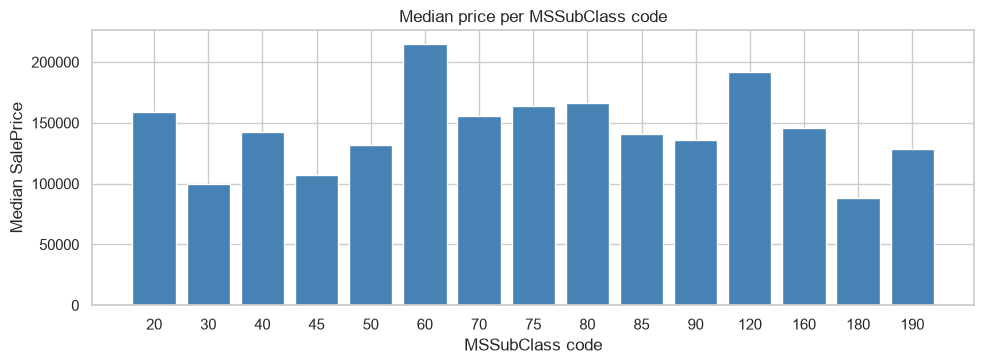

In [11]:
mssub_names = {20: "1-story, built 1946 or later", 30: "1-story, built before 1946", 40: "1-story with finished attic",
               45: "1.5-story, unfinished", 50: "1.5-story, finished", 60: "2-story, built 1946 or later",
               70: "2-story, built before 1946", 75: "2.5-story", 80: "split or multi-level", 85: "split foyer",
               90: "duplex", 120: "1-story PUD, 1946 or later", 150: "1.5-story PUD",
               160: "2-story PUD, 1946 or later", 180: "PUD multi-level / split", 190: "2-family conversion"}

mssub = df.groupby("MSSubClass")["SalePrice"].agg(["count", "median"])
mssub.insert(0, "meaning", mssub.index.map(mssub_names))
display(mssub)

plt.figure(figsize=(10, 3.8))
plt.bar(mssub.index.astype(str), mssub["median"], color="steelblue")
plt.xlabel("MSSubClass code")
plt.ylabel("Median SalePrice")
plt.title("Median price per MSSubClass code")
plt.tight_layout()
plt.show()

#### `MoSold`
Mont sold (1-12). Does the price go up or down in a straight line with the month number?


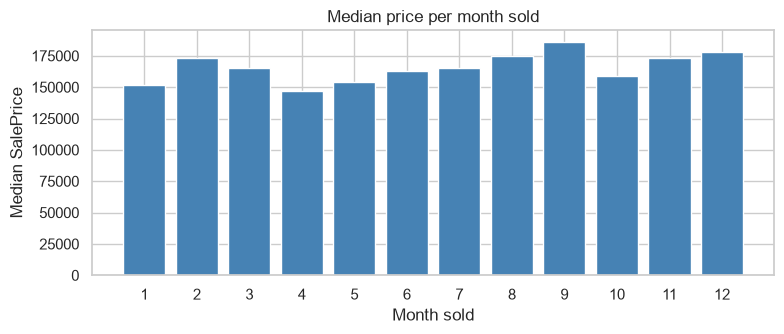

In [12]:
month_price = df.groupby("MoSold")["SalePrice"].median()
plt.figure(figsize=(8, 3.5))
plt.bar(month_price.index.astype(str), month_price.values, color="steelblue")
plt.xlabel("Month sold")
plt.ylabel("Median SalePrice")
plt.title("Median price per month sold")
plt.tight_layout()
plt.show()

#### `OverallQual` and `OverallCond`
`OverallQual` and `OverallCond` are scores. Does a higher score mean a higher price, step by step?


In [13]:
pd.DataFrame({
    "OverallQual": df.groupby("OverallQual")["SalePrice"].median(),
    "OverallCond": df.groupby("OverallCond")["SalePrice"].median(),
}).T

,1,2,3,4,5,6,7,8,9,10
OverallQual,"50,150.000","60,000.000","86,250.000","108,000.000","133,000.000","160,000.000","200,141.000","269,750.000","345,000.000","432,390.000"
OverallCond,"61,000.000","85,000.000","89,500.000","115,000.000","185,000.000","142,750.000","145,000.000","142,500.000","176,200.000",NaN


#### The rating columns
 Ten text columns use letters. Here are all ten with every value they contain. Reading the letters from low to high: `Po` = poor, `Fa` = fair, `TA` = typical/average, `Gd` = good, `Ex` = excellent, and `NA` = the house doesn't have it (no basement, no garage...).

In [14]:
rating_cols = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC",
               "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]
scale_order = ["Po", "Fa", "TA", "Gd", "Ex"]

rows = []
for c in rating_cols:
    found = df[c].fillna("NA").unique().tolist()
    ordered = [v for v in scale_order if v in found] + (["NA"] if "NA" in found else [])
    rows.append({"column": c,
                 "values found (low to high)": ", ".join(ordered),
                 "only uses Po/Fa/TA/Gd/Ex/NA": set(found) <= set(scale_order + ["NA"]),
                 "houses with NA": int(df[c].isna().sum())})
pd.DataFrame(rows).set_index("column")

,values found (low to high),only uses Po/Fa/TA/Gd/Ex/NA,houses with NA
column,,,
ExterQual,"Fa, TA, Gd, Ex",True,0
ExterCond,"Po, Fa, TA, Gd, Ex",True,0
BsmtQual,"Fa, TA, Gd, Ex, NA",True,37
BsmtCond,"Po, Fa, TA, Gd, NA",True,37
HeatingQC,"Po, Fa, TA, Gd, Ex",True,0
KitchenQual,"Fa, TA, Gd, Ex",True,0
FireplaceQu,"Po, Fa, TA, Gd, Ex, NA",True,690
GarageQual,"Po, Fa, TA, Gd, Ex, NA",True,81
GarageCond,"Po, Fa, TA, Gd, Ex, NA",True,81


Do the letters really work as a scale? Median price for two of them, from low to high:

In [15]:
for c in ["ExterQual", "KitchenQual"]:
    present = [v for v in scale_order if v in df[c].unique()]
    print(c)
    display(df.groupby(c)["SalePrice"].agg(["count", "median"]).reindex(present))

ExterQual


,count,median
ExterQual,,
Fa,14,"82,250.000"
TA,906,"139,450.000"
Gd,488,"220,000.000"
Ex,52,"364,606.500"


KitchenQual


,count,median
KitchenQual,,
Fa,39,"115,000.000"
TA,735,"137,000.000"
Gd,586,"201,400.000"
Ex,100,"316,750.000"


**Observed**
- `MSSubClass`: price does not follow the code. 60 is expensive, 70 drops back, 30 is cheap, 120 jumps up again. The codes are labels, not a scale.
- `MoSold`: price does not climb or fall with the month number. It moves up and down. Also, month 12 is next to month 1 in real life, but a plain number would put them far apart.
- `OverallQual`: price goes up at every step. That is a real scale. `OverallCond` does not go up at every step, so it is a weaker scale.
- All ten rating columns use only the same six values (`Po`, `Fa`, `TA`, `Gd`, `Ex`, `NA`).
- For `ExterQual` and `KitchenQual`, price rises with each step up the letters. So the order is real.

**Action**
- Turn `MSSubClass` and `MoSold` into text, so they are treated as labels.
- Keep `OverallQual` and `OverallCond` as numbers (the model can still use them).
- Turn the ten rating columns into numbers: `NA` = 0, `Po` = 1, `Fa` = 2, `TA` = 3, `Gd` = 4, `Ex` = 5. (`PoolQC` is dropped in 1.7, so nine get mapped.)


### 1.5. Do the numbers add up?

In [16]:
checks = pd.Series({
    "GrLivArea is not 1stFlrSF + 2ndFlrSF + LowQualFinSF": int((df["GrLivArea"] != df["1stFlrSF"] + df["2ndFlrSF"] + df["LowQualFinSF"]).sum()),
    "TotalBsmtSF is not BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF": int((df["TotalBsmtSF"] != df["BsmtFinSF1"] + df["BsmtFinSF2"] + df["BsmtUnfSF"]).sum()),
}, name="houses that don't add up")
checks.to_frame()

,houses that don't add up
GrLivArea is not 1stFlrSF + 2ndFlrSF + LowQualFinSF,0
TotalBsmtSF is not BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF,0


**Observed**: both checks give 0, so the area columns add up exactly.

**Action**: it is safe to add area columns together later (for example `TotalSF` in 2.2).

### 1.6. Outliers

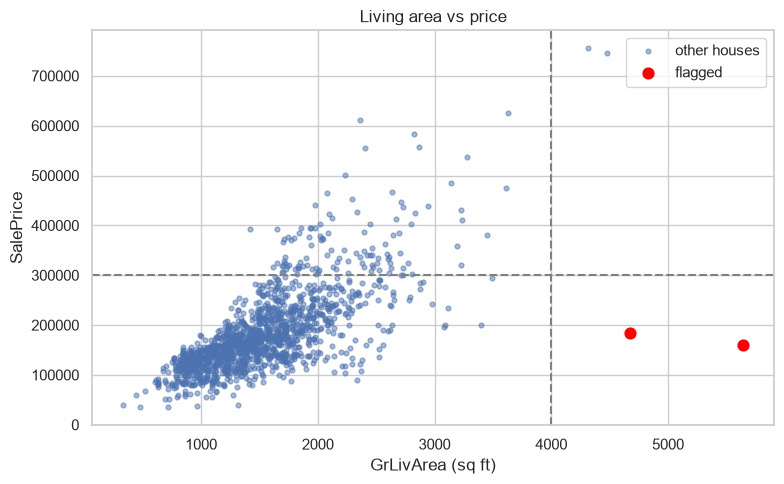

Houses flagged: 2


,GrLivArea,SalePrice,OverallQual,Neighborhood,SaleCondition
523,4676,184750,10,Edwards,Partial
1298,5642,160000,10,Edwards,Partial


In [17]:
OUT_AREA, OUT_PRICE = 4000, 300000
outlier_rule = (df["GrLivArea"] > OUT_AREA) & (df["SalePrice"] < OUT_PRICE)

plt.figure(figsize=(8, 5))
plt.scatter(df.loc[~outlier_rule, "GrLivArea"], df.loc[~outlier_rule, "SalePrice"], s=12, alpha=0.5, label="other houses")
plt.scatter(df.loc[outlier_rule, "GrLivArea"], df.loc[outlier_rule, "SalePrice"], s=60, color="red", label="flagged")
plt.axvline(OUT_AREA, color="gray", linestyle="--")
plt.axhline(OUT_PRICE, color="gray", linestyle="--")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice")
plt.title("Living area vs price")
plt.legend()
plt.tight_layout()
plt.show()

print("Houses flagged:", int(outlier_rule.sum()))
display(df.loc[outlier_rule, ["GrLivArea", "SalePrice", "OverallQual", "Neighborhood", "SaleCondition"]])


Does removing these two houses change the link between area and price? (correlation between `GrLivArea` and log price)

In [18]:
log_price_all = np.log1p(df["SalePrice"])
r_with = df["GrLivArea"].corr(log_price_all)
r_without = df.loc[~outlier_rule, "GrLivArea"].corr(log_price_all[~outlier_rule])
print(f"With the 2 houses:    {r_with:.3f}")
print(f"Without the 2 houses: {r_without:.3f}")

With the 2 houses:    0.701
Without the 2 houses: 0.725


In 1.1 we also saw other big values (`LotArea`, `LotFrontage`, `MasVnrArea`, `TotalBsmtSF`). Here is the house with the biggest value of each, and its price:

In [19]:
rows = []
for c in ["LotArea", "LotFrontage", "MasVnrArea", "TotalBsmtSF"]:
    i = df[c].idxmax()
    rows.append({"column": c,
                 "75% of houses are below": df[c].quantile(0.75),
                 "biggest value": df.loc[i, c],
                 "its GrLivArea": df.loc[i, "GrLivArea"],
                 "its SalePrice": df.loc[i, "SalePrice"],
                 "is one of the 2 flagged houses": bool(outlier_rule.loc[i])})
pd.DataFrame(rows).set_index("column")

,75% of houses are below,biggest value,its GrLivArea,its SalePrice,is one of the 2 flagged houses
column,,,,,
LotArea,"11,601.500","215,245.000",2036,375000,False
LotFrontage,80.000,313.000,2069,242000,False
MasVnrArea,166.000,"1,600.000",1950,239000,False
TotalBsmtSF,"1,298.250","6,110.000",5642,160000,True


**Observed**
- The trend is clear: bigger house, higher price.
- Two houses (red) are way off: 4,676 and 5,642 sq ft but sold for only 184,750 and 160,000, even though both have the top quality score (10). Both are `Partial` sales in `Edwards`. `Partial` means the house was not finished when it was assessed, so the price probably does not match the size.
- Two other very big houses (about 4,300-4,500 sq ft, about 750k) follow the trend, so we keep them. That is why the rule needs both "big area" and "low price".
- After removing the two flagged houses, the correlation between area and price goes up. So those two houses were pulling the relationship down.
- The other big values in the last table are rare. Unlike the two flagged houses, none of them comes with a price that clearly breaks the size pattern.

**Action**
- Remove the 2 flagged houses (0.14% of the data).
- Keep the other big values. The log step in the pipeline (2.4) makes them less extreme.

### 1.7. Columns near constant

In [20]:
top_share = pd.Series({c: df[c].value_counts(dropna=False, normalize=True).iloc[0] for c in df.columns.drop("SalePrice")})

near_const_report = top_share[top_share >= 0.99].sort_values(ascending=False).to_frame("pct share common value")
near_const_report["most common value"] = [("NA (no pool)" if pd.isna(df[c].value_counts(dropna=False).index[0])
                                          else df[c].value_counts(dropna=False).index[0]) for c in near_const_report.index]
display(near_const_report)

,pct share common value,most common value
Utilities,0.999,AllPub
Street,0.996,Pave
PoolArea,0.995,0
PoolQC,0.995,NA (no pool)


**Observed**: Four columns have the same value in at least 99.5% of houses: `Utilities` (99.9% `AllPub`), `Street` (99.6% `Pave`), `PoolArea` and `PoolQC` (99.5%, only 7 houses have a pool).

**Action**: drop these four columns ('Street', 'Utilities', 'PoolArea', 'PoolQC'). We only looked at how often values repeat, never at the price, so nothing leaks.


### 1.8. One more column to drop: `GarageYrBlt`

`GarageYrBlt` is year garage was built

In [21]:
has_garage = df["GarageYrBlt"].notna()
print("Houses with no garage year:", int((~has_garage).sum()))
print("Correlation of GarageYrBlt with YearBuilt (houses that have a garage):",
      round(df.loc[has_garage, "GarageYrBlt"].corr(df.loc[has_garage, "YearBuilt"]), 3))

Houses with no garage year: 81
Correlation of GarageYrBlt with YearBuilt (houses that have a garage): 0.826


**Observed**
- 81 houses have no garage year (they have no garage).
- For houses with a garage, the garage year is very close to the year the house was built.

**Action**: drop `GarageYrBlt`. It mostly repeats `YearBuilt`, and filling the 81 gaps would mean inventing a year. `GarageType = None` still tells us there is no garage.


### 1.9. Apply the cleaning

Everything above in one function. The function can be reused later on Kaggle's `test.csv` (use `drop_outliers=False` there, because we never remove rows from a test file).

What it does:
1. Remove the 2 flagged houses (only when `drop_outliers=True`).
2. Drop the near-constant columns and `GarageYrBlt`.
3. Fill the "none" columns with `None` (text) or `0` (`MasVnrArea`).
4. Turn `MSSubClass` and `MoSold` into text.
5. Turn the rating letters into 0-5.
6. Leave `LotFrontage` and `Electrical` empty for the pipeline.

In [22]:
rating_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
drop_cols = near_constant + ["GarageYrBlt"]


def clean_data(data: pd.DataFrame, drop_outliers: bool = False) -> pd.DataFrame:
    out = data.drop(columns=["Id"], errors="ignore").copy()

    if drop_outliers:
        out = out.loc[~((out["GrLivArea"] > OUT_AREA) & (out["SalePrice"] < OUT_PRICE))]

    out = out.drop(columns=drop_cols, errors="ignore")

    none_cols = [c for c in absent_cat_cols if c in out.columns] + ["MasVnrType"]
    out[none_cols] = out[none_cols].fillna("None")
    out["MasVnrArea"] = out["MasVnrArea"].fillna(0)

    out["MSSubClass"] = out["MSSubClass"].astype(str)
    out["MoSold"] = out["MoSold"].astype(str)

    for c in rating_cols:
        if c in out.columns:
            out[c] = out[c].map(rating_map)

    text_cols = out.select_dtypes(exclude="number").columns
    out[text_cols] = out[text_cols].apply(lambda s: s.str.strip())
    return out


df_clean = clean_data(df, drop_outliers=True)

mapped = [c for c in rating_cols if c in df_clean.columns]
left = df_clean.isna().sum()
print("Rows, columns:", df.shape, "->", df_clean.shape)
print("Rating columns turned into numbers:", len(mapped), mapped)
print("Rating values that didn't match the map:", int(df_clean[mapped].isna().sum().sum()))
print()
print("Still empty:")
print(left[left > 0].to_string())

NameError: name 'near_constant' is not defined

Before and after, for three houses that have no garage:

In [ ]:
demo_idx = df.index[df["GarageType"].isna()][:3]
demo_cols = ["GarageType", "GarageQual", "BsmtQual", "FireplaceQu", "MasVnrType", "ExterQual"]
print("RAW:")
display(df.loc[demo_idx, demo_cols])
print("CLEAN:")
display(df_clean.loc[demo_idx, demo_cols])

RAW:


,GarageType,GarageQual,BsmtQual,FireplaceQu,MasVnrType,ExterQual
39,NaN,NaN,NaN,NaN,None,TA
48,NaN,NaN,TA,NaN,None,TA
78,NaN,NaN,TA,NaN,None,TA


CLEAN:


,GarageType,GarageQual,BsmtQual,FireplaceQu,MasVnrType,ExterQual
39,None,0,0,0,None,3
48,None,0,3,0,None,3
78,None,0,3,0,None,3


- 1,460 rows and 80 columns became 1,458 rows and 75 columns (2 flagged houses, 4 near-constant columns and `GarageYrBlt` are gone).
- Every rating letter was matched. Nothing turned into a new missing value.
- Only `LotFrontage` (259) and `Electrical` (1) are still empty. Those are the two really-missing columns from 1.2.
- The before/after table shows the changes: `NaN` became `None` where the house has no garage, basement or fireplace, and `ExterQual` letters became numbers (for example `TA` became 3).


## 2. DATA PREPARATION

**Goal**: turn the cleaned table into numbers a model can use, without leaking anything from the validation set.

**Order**: split first, then build new columns, then fit one pipeline on the training set only.


### 2.1. Split into train and validation

We split 80/20. Price is split into 5 equal groups and each group is shared between train and validation, so both sets have cheap and expensive houses.

We call the 20% part validation, not test, because our's own `test.csv` has no prices.

We also create `log1p(SalePrice)`. The reason is in 3.1.

In [ ]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns="SalePrice")
y = df_clean["SalePrice"]

price_group = pd.qcut(y, q=5, labels=False)
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=price_group)

y_train_log, y_valid_log = np.log1p(y_train), np.log1p(y_valid)

print("Train:", X_train.shape, "| Validation:", X_valid.shape)
pd.DataFrame({"train": y_train.describe(), "validation": y_valid.describe()}).round(0)

Train: (1166, 74) | Validation: (292, 74)


,train,validation
count,"1,166.000",292.000
mean,"182,184.000","175,937.000"
std,"82,276.000","67,150.000"
min,"34,900.000","37,900.000"
25%,"130,000.000","128,500.000"
50%,"163,000.000","161,500.000"
75%,"214,000.000","214,925.000"
max,"755,000.000","538,000.000"


**Observed**
- 1,166 houses to train, 292 to validate.
- The quartiles are close: 130,000 / 163,000 / 214,000 in train vs 128,500 / 161,500 / 214,925 in validation. The median is 163,000 vs 161,500.
- But the validation mean is lower (175,937 vs 182,184, about 3% less), and the validation set has no very expensive houses (max 538,000 vs 755,000 in train, and a smaller spread).

**Action**: the split is fair for most houses, but validation is a bit "easier" at the top end. Keep this in mind when reading scores. Cross-validation on the train set later will give a steadier number.


### 2.2. New columns

We combine related columns into one, so the model sees the idea directly:
- `TotalSF` = basement + 1st floor + 2nd floor area
- `TotalBath` = full baths + half of the half baths (above ground and basement)
- `HouseAge` = year sold minus year built
- `RemodAge` = year sold minus year remodelled

Are they better than the columns they come from? Correlation with log price (train only). We also test a `TotalPorchSF` (all porches added up) to see if it helps.


In [ ]:
def add_features(d: pd.DataFrame) -> pd.DataFrame:
    out = d.copy()
    out["TotalSF"] = out["TotalBsmtSF"] + out["1stFlrSF"] + out["2ndFlrSF"]
    out["TotalBath"] = out["FullBath"] + 0.5 * out["HalfBath"] + out["BsmtFullBath"] + 0.5 * out["BsmtHalfBath"]
    out["HouseAge"] = (out["YrSold"] - out["YearBuilt"]).clip(lower=0)     # clip: never below 0
    out["RemodAge"] = (out["YrSold"] - out["YearRemodAdd"]).clip(lower=0)
    return out

X_train_fe = add_features(X_train)
X_valid_fe = add_features(X_valid)

porch_total = X_train[["OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]].sum(axis=1)   # tested only

compare = [
    ("TotalSF (new)",      X_train_fe["TotalSF"]),
    ("GrLivArea",          X_train_fe["GrLivArea"]),
    ("TotalBsmtSF",        X_train_fe["TotalBsmtSF"]),
    ("1stFlrSF",           X_train_fe["1stFlrSF"]),
    ("TotalBath (new)",    X_train_fe["TotalBath"]),
    ("FullBath",           X_train_fe["FullBath"]),
    ("HalfBath",           X_train_fe["HalfBath"]),
    ("HouseAge (new)",     X_train_fe["HouseAge"]),
    ("YearBuilt",          X_train_fe["YearBuilt"]),
    ("RemodAge (new)",     X_train_fe["RemodAge"]),
    ("YearRemodAdd",       X_train_fe["YearRemodAdd"]),
    ("TotalPorchSF (tested)", porch_total),
    ("OpenPorchSF",        X_train_fe["OpenPorchSF"]),
]
display(pd.DataFrame({"correlation with log price": {name: s.corr(y_train_log) for name, s in compare}}))

,correlation with log price
TotalSF (new),0.831
GrLivArea,0.739
TotalBsmtSF,0.649
1stFlrSF,0.629
TotalBath (new),0.678
FullBath,0.601
HalfBath,0.321
HouseAge (new),-0.576
YearBuilt,0.575
RemodAge (new),-0.574


Houses sold before the year they were built (age below 0, set to 0): 0


**Observed**
- `TotalSF` (0.831) beats every piece it is made of: `GrLivArea` 0.739, `TotalBsmtSF` 0.649, `1stFlrSF` 0.629.
- `TotalBath` (0.678) beats `FullBath` (0.601) and `HalfBath` (0.321).
- `HouseAge` (-0.576) and `YearBuilt` (0.575) have the same strength with opposite signs. `RemodAge` (-0.574) and `YearRemodAdd` (0.571) too. They look like the same information.
- `TotalPorchSF` (0.193) is weaker than `OpenPorchSF` alone (0.318).

**Action**
- Keep `TotalSF`, `TotalBath`, `HouseAge` and `RemodAge`.
- Do not build `TotalPorchSF` (adding the porches together made the signal weaker).
- `HouseAge` and `RemodAge` are easier to read than raw years. Whether the year columns stay is decided in 2.3.


### 2.3. Drop columns that copy another column

If two columns move almost exactly together, the model gets the same information twice. We list every pair with a correlation of 0.95 or more (in absolute value) in the train set.


In [ ]:
num_fe = X_train_fe.select_dtypes(include="number")
corr_fe = num_fe.corr()

pairs = (corr_fe.where(np.triu(np.ones(corr_fe.shape, dtype=bool), k=1))
                .stack().rename("correlation").reset_index())
pairs.columns = ["column 1", "column 2", "correlation"]
copy_pairs = pairs[pairs["correlation"].abs() >= 0.95].sort_values("correlation", key=abs, ascending=False)
display(copy_pairs.reset_index(drop=True))

copycat_drop = ["YearBuilt", "YearRemodAdd", "GarageCond"]
X_train_fe = X_train_fe.drop(columns=copycat_drop)
X_valid_fe = X_valid_fe.drop(columns=copycat_drop)
print("Dropped:", copycat_drop)
print("Train shape now:", X_train_fe.shape)

,column 1,column 2,correlation
0,YearBuilt,HouseAge,-0.999
1,YearRemodAdd,RemodAge,-0.998
2,GarageQual,GarageCond,0.954


Dropped: ['YearBuilt', 'YearRemodAdd', 'GarageCond']
Train shape now: (1166, 75)


**Observed**: three pairs are almost identical: `YearBuilt` vs `HouseAge` (-0.999), `YearRemodAdd` vs `RemodAge` (-0.998), and `GarageQual` vs `GarageCond` (0.954).

**Action**
- Drop `YearBuilt` and `YearRemodAdd`.
- Drop `GarageCond` and keep `GarageQual`. 
- Less strong overlaps (0.8 to 0.9) are shown in 3.2.

### 2.4. The pipeline

We have three kinds of columns. Each kind gets its own steps. Every number the steps learn (medians, skew, scaling, categories) comes from the train set only.


In [ ]:
area_cols = ["LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
             "1stFlrSF", "2ndFlrSF", "LowQualFinSF", "GrLivArea", "GarageArea", "WoodDeckSF", "OpenPorchSF",
             "EnclosedPorch", "3SsnPorch", "ScreenPorch", "MiscVal", "TotalSF"]

continuous_cols = [c for c in area_cols if c in X_train_fe.columns]
other_num_cols = [c for c in X_train_fe.select_dtypes(include="number").columns if c not in continuous_cols]
cat_cols = X_train_fe.select_dtypes(exclude="number").columns.tolist()

pd.DataFrame({
    "group": ["Areas and money (can be any size)", "Other numbers (counts, years, ratings)", "Text columns"],
    "how many": [len(continuous_cols), len(other_num_cols), len(cat_cols)],
    "examples": [", ".join(continuous_cols[:4]), ", ".join(other_num_cols[:4]), ", ".join(cat_cols[:4])],
    "steps": ["fill gaps with median -> log (only if it helps) -> scale",
              "fill gaps with median -> scale",
              "fill gaps with most common value -> one-hot (rare categories grouped)"],
}).set_index("group")

,how many,examples,steps
group,,,
Areas and money (can be any size),19,"LotFrontage, LotArea, MasVnrArea, BsmtFinSF1",fill gaps with median -> log (only if it helps...
"Other numbers (counts, years, ratings)",23,"OverallQual, OverallCond, ExterQual, ExterCond",fill gaps with median -> scale
Text columns,33,"MSSubClass, MSZoning, Alley, LotShape",fill gaps with most common value -> one-hot (r...


Text columns become one-hot columns (one 0/1 column per category). How many would that be?

In [ ]:
n_categories = X_train_fe[cat_cols].nunique().sort_values(ascending=False)
rare = sum(int((X_train_fe[c].value_counts() < 10).sum()) for c in cat_cols)

print(f"{len(cat_cols)} text columns, {int(n_categories.sum())} categories in total")
print(f"Categories with fewer than 10 houses in train: {rare}")
print()
n_categories.head(8).to_frame("number of categories")

33 text columns, 236 categories in total
Categories with fewer than 10 houses in train: 62



,number of categories
Neighborhood,25
Exterior2nd,16
MSSubClass,15
Exterior1st,15
MoSold,12
SaleType,9
Condition1,9
HouseStyle,8


**Observed**
- 33 text columns would turn into the number of one-hot columns shown above, for only 1,166 training houses. Many categories are rare (the count of categories with fewer than 10 houses is printed above).
- Earlier we also saw that 3 of 25 neighbourhoods have fewer than 10 houses (3.5).

**Action**
- Group every category with fewer than 10 houses into one "other" column per text column (`min_frequency=10`). The model can't learn anything stable from 2 or 3 houses.
- Fill `LotFrontage` with the median of the **same neighbourhood**, because lot frontage differs a lot between areas (2.5 shows the numbers).
- Use log only on area columns that are skewed **and** get better with log (see 2.5). A plain "log everything skewed" rule can make some columns worse.


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


class NeighborhoodMedianImputer(BaseEstimator, TransformerMixin):
    """Fill empty `column` with the median of the same `group` (learned on train)."""
    def __init__(self, column="LotFrontage", group="Neighborhood"):
        self.column = column
        self.group = group

    def fit(self, X, y=None):
        self.group_median_ = X.groupby(self.group)[self.column].median()
        self.global_median_ = X[self.column].median()
        return self

    def transform(self, X):
        X = X.copy()
        fill = X[self.group].map(self.group_median_).fillna(self.global_median_)
        X[self.column] = X[self.column].fillna(fill)
        return X


class SmartLog1p(BaseEstimator, TransformerMixin):
    """log1p only on columns that are skewed (> threshold) AND less skewed after the log (checked on train)."""
    def __init__(self, threshold=0.75):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        before = X.skew()
        after = np.log1p(X.clip(lower=0)).skew()
        skewed = before > self.threshold
        better = after.abs() < before.abs()
        self.skew_before_ = before.values
        self.skew_after_ = after.values
        self.log_idx_ = np.where((skewed & better).values)[0]
        self.skipped_idx_ = np.where((skewed & ~better).values)[0]
        return self

    def transform(self, X):
        X = np.array(X, dtype=float, copy=True)
        X[:, self.log_idx_] = np.log1p(np.clip(X[:, self.log_idx_], 0, None))
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


continuous_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", SmartLog1p(0.75)),
    ("scaler", StandardScaler()),
])
other_num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)),
])

column_transformer = ColumnTransformer([
    ("continuous", continuous_pipe, continuous_cols),
    ("other_num", other_num_pipe, other_num_cols),
    ("cat", cat_pipe, cat_cols),
])

preprocessor = Pipeline([
    ("lot_frontage", NeighborhoodMedianImputer("LotFrontage", "Neighborhood")),
    ("columns", column_transformer),
])
print("Pipeline ready")

Pipeline ready


### 2.5. Run the pipeline (fit on train, then apply to validation)

In [ ]:
X_train_prepared = preprocessor.fit_transform(X_train_fe)
X_valid_prepared = preprocessor.transform(X_valid_fe)

feature_names = preprocessor.named_steps["columns"].get_feature_names_out()
X_train_prepared_df = pd.DataFrame(X_train_prepared, columns=feature_names, index=X_train_fe.index)
X_valid_prepared_df = pd.DataFrame(X_valid_prepared, columns=feature_names, index=X_valid_fe.index)

n_onehot = sum(name.startswith("cat__") for name in feature_names)
print("Prepared train:     ", X_train_prepared_df.shape)
print("Prepared validation:", X_valid_prepared_df.shape)
print("Empty cells left (train / validation):", int(X_train_prepared_df.isna().sum().sum()), "/", int(X_valid_prepared_df.isna().sum().sum()))
print(f"One-hot columns: {n_onehot} (would be {int(n_categories.sum())} without grouping rare categories)")
print()

lot_by_nb = X_train_fe.groupby("Neighborhood")["LotFrontage"].median()
print(f"LotFrontage empty in train: {int(X_train_fe['LotFrontage'].isna().sum())}")
print(f"Median LotFrontage overall: {X_train_fe['LotFrontage'].median():.0f} | per neighbourhood: from {lot_by_nb.min():.0f} to {lot_by_nb.max():.0f}")


Prepared train:      (1166, 237)
Prepared validation: (292, 237)
Empty cells left (train / validation): 0 / 0
One-hot columns: 195 (would be 236 without grouping rare categories)

LotFrontage empty in train: 209
Median LotFrontage overall: 69 | per neighbourhood: from 21 to 93


Which area columns got the log, and which did not?

In [ ]:
log_step = preprocessor.named_steps["columns"].named_transformers_["continuous"].named_steps["log"]

decision = np.full(len(continuous_cols), "not skewed enough", dtype=object)
decision[log_step.log_idx_] = "log applied"
decision[log_step.skipped_idx_] = "skipped (log does not help)"

skew_table = pd.DataFrame({"skew before": log_step.skew_before_,
                           "skew after log": log_step.skew_after_,
                           "decision": decision}, index=continuous_cols).sort_values("skew before", ascending=False)
skew_table

,skew before,skew after log,decision
MiscVal,22.185,5.382,log applied
LotArea,13.844,-0.265,log applied
3SsnPorch,9.970,7.574,log applied
LowQualFinSF,8.613,7.083,log applied
ScreenPorch,4.165,3.082,log applied
BsmtFinSF2,4.111,2.476,log applied
EnclosedPorch,2.996,1.989,log applied
MasVnrArea,2.868,0.550,log applied
OpenPorchSF,2.354,-0.021,log applied
LotFrontage,1.839,-0.878,log applied


A plain example: `LotArea` before and after the log.

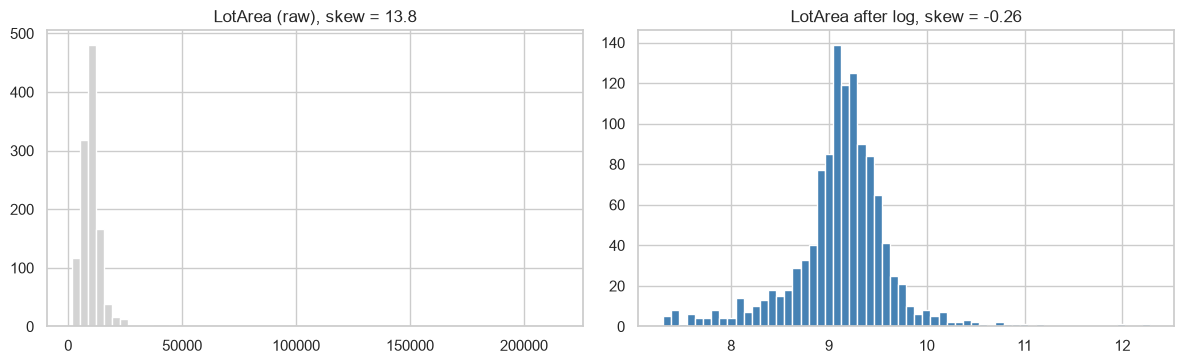

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
lot = X_train_fe["LotArea"]
axes[0].hist(lot, bins=60, color="lightgray")
axes[0].set_title(f"LotArea (raw), skew = {lot.skew():.1f}")
axes[1].hist(np.log1p(lot), bins=60, color="steelblue")
axes[1].set_title(f"LotArea after log, skew = {np.log1p(lot).skew():.2f}")
plt.tight_layout()
plt.show()

And what a few rows look like before and after the pipeline:

In [ ]:
demo_cols = ["LotArea", "GrLivArea", "OverallQual", "ExterQual"]
prep_names = [("continuous__" if c in continuous_cols else "other_num__") + c for c in demo_cols]

print("Before (cleaned values):")
display(X_train_fe[demo_cols].head(3))
print("After (scaled numbers, mean 0 and spread 1):")
display(X_train_prepared_df[prep_names].head(3).rename(columns=dict(zip(prep_names, demo_cols))))

nb_cols = [c for c in feature_names if c.startswith("cat__Neighborhood_")]
print("Text to one-hot, first 3 houses:")
pd.DataFrame({"Neighborhood": X_train_fe["Neighborhood"].head(3),
              "column switched on": X_train_prepared_df[nb_cols].head(3).idxmax(axis=1)})

Before (cleaned values):


,LotArea,GrLivArea,OverallQual,ExterQual
307,7920,1406,6,3
639,3982,1567,8,4
1084,13031,1498,6,3


After (scaled numbers, mean 0 and spread 1):


,LotArea,GrLivArea,OverallQual,ExterQual
307,-0.270,-0.055,-0.066,-0.689
639,-1.629,0.267,1.367,1.036
1084,0.715,0.133,-0.066,-0.689


Text to one-hot, first 3 houses:


,Neighborhood,column switched on
307,IDOTRR,cat__Neighborhood_IDOTRR
639,Blmngtn,cat__Neighborhood_Blmngtn
1084,Gilbert,cat__Neighborhood_Gilbert


**Observed**
- Train and validation have the same columns, and there is no empty cell left anywhere.
- Grouping rare categories makes the one-hot part smaller (compare the two numbers above).
- `LotFrontage`: 209 empty cells in train. The overall median is 69, but the neighbourhood medians go from 21 to 93, so a single overall value would be wrong for many houses.
- Log works for most area columns. `LotArea` goes from skew 13.8 to -0.27 (the picture shows the long tail gone). `GrLivArea` goes from 1.04 to -0.07 and `1stFlrSF` from 0.95 to 0.03.
- `BsmtUnfSF` is skipped: its skew would go from 0.91 to -2.11, which is worse. That is what the "only if it helps" rule is for.
- Some columns stay skewed even after the log: `MiscVal` 22.2 to 5.4, `3SsnPorch` 10.0 to 7.6, `LowQualFinSF` 8.6 to 7.1, `ScreenPorch` 4.2 to 3.1. Most houses have 0 in these columns, so the log can't fix the big pile at 0.
- The before/after table shows the idea: raw areas become small numbers centred on 0, and each house's neighbourhood becomes one switched-on column.

**Action**
- Use this prepared data for modelling.
- Accept that the mostly-zero columns stay skewed. Tree models don't mind. For linear models, a simple "has this feature or not" column would be the next idea to try.


## 3. EDA

We look only at the **train set**, after cleaning and the new columns, but before scaling and log, so numbers are still in normal units (sq ft, USD).


In [ ]:
eda_df = X_train_fe.copy()
eda_df["SalePrice"] = y_train
eda_df["LogSalePrice"] = y_train_log
print(eda_df.shape)

(1166, 77)


### 3.1. The price itself

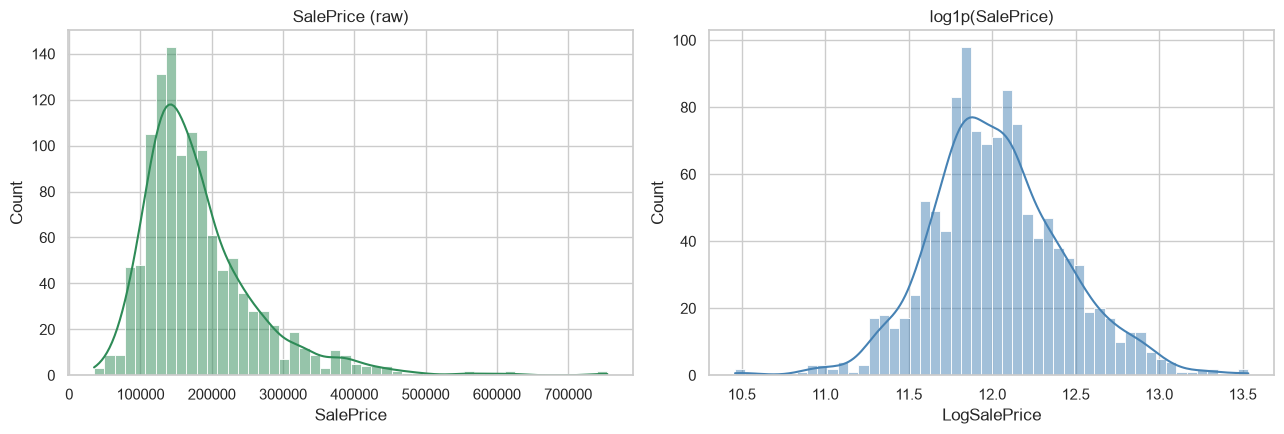

Skewness  raw: 1.97 | after log: 0.23
Kurtosis  raw: 6.71 | after log: 0.78


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(eda_df["SalePrice"], bins=50, kde=True, ax=axes[0], color="seagreen")
axes[0].set_title("SalePrice (raw)")
sns.histplot(eda_df["LogSalePrice"], bins=50, kde=True, ax=axes[1], color="steelblue")
axes[1].set_title("log1p(SalePrice)")
plt.tight_layout()
plt.show()

print(f"Skewness  raw: {eda_df['SalePrice'].skew():.2f} | after log: {eda_df['LogSalePrice'].skew():.2f}")
print(f"Kurtosis  raw: {eda_df['SalePrice'].kurt():.2f} | after log: {eda_df['LogSalePrice'].kurt():.2f}")


(Skewness: 0 means balanced, bigger than 0 means a long tail to the right. Kurtosis: bigger means more extreme values far from the middle.)

**Observed**
- Raw price has a long tail to the right (skewness 1.97, kurtosis 6.71): most houses are around 100k-200k and a few go up to 755,000.
- After the log, the shape is close to balanced (skewness 0.23, kurtosis 0.78).

**Action**: model `log1p(SalePrice)`, and turn predictions back with `expm1`. The log also stops a few very expensive houses from dominating the errors.


### 3.2. What goes with price? (numbers)

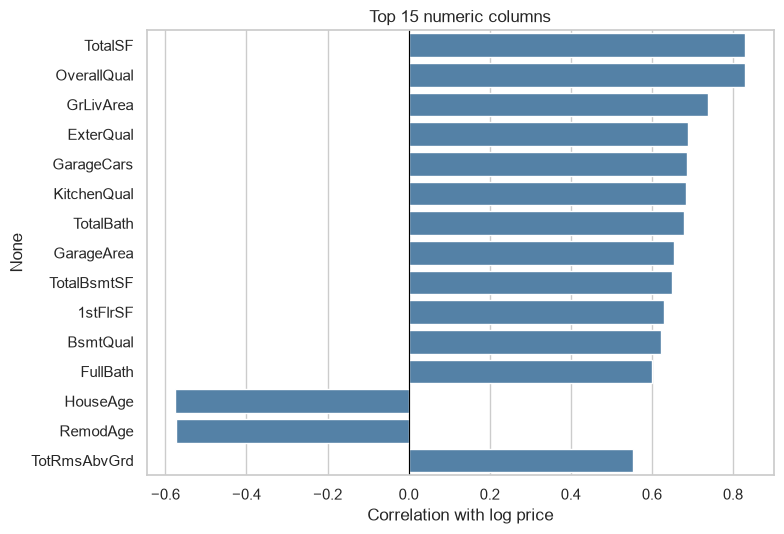

TotalSF         0.831
OverallQual     0.830
GrLivArea       0.739
ExterQual       0.690
GarageCars      0.687
KitchenQual     0.683
TotalBath       0.678
GarageArea      0.655
TotalBsmtSF     0.649
1stFlrSF        0.629
BsmtQual        0.623
FullBath        0.601
HouseAge       -0.576
RemodAge       -0.574
TotRmsAbvGrd    0.554


In [ ]:
num_eda = eda_df.select_dtypes(include="number").drop(columns="SalePrice")
corr_target = num_eda.corr()["LogSalePrice"].drop("LogSalePrice").sort_values(ascending=False)

top = corr_target.abs().sort_values(ascending=False).head(15).index
plt.figure(figsize=(8, 5.5))
sns.barplot(x=corr_target[top].values, y=top, color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Correlation with log price")
plt.title("Top 15 numeric columns")
plt.tight_layout()
plt.show()

print(corr_target.loc[top].round(3).to_string())

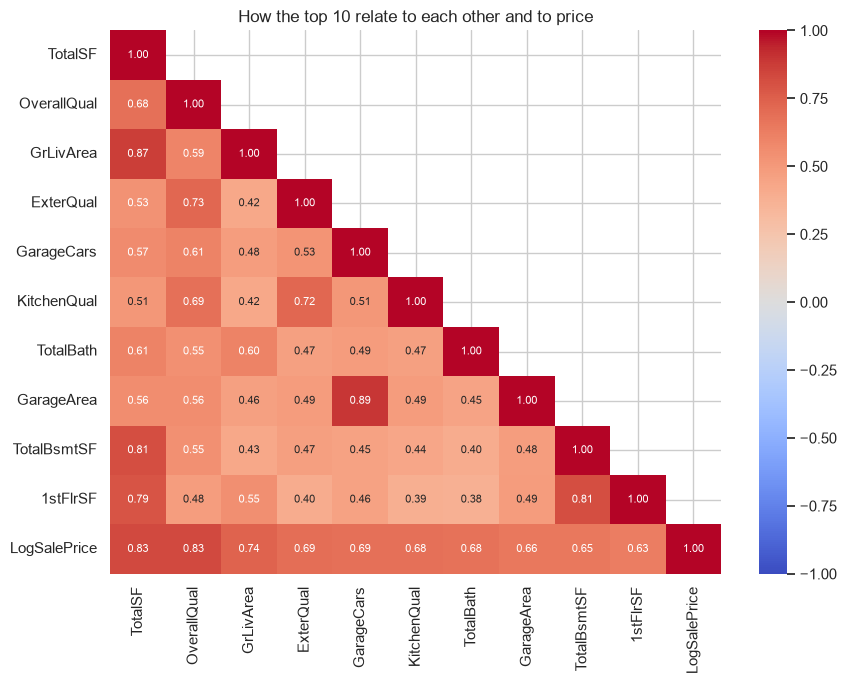

In [ ]:
top10 = corr_target.abs().sort_values(ascending=False).head(10).index.tolist()
corr_top = num_eda[top10 + ["LogSalePrice"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_top, mask=np.triu(np.ones_like(corr_top, dtype=bool), k=1), cmap="coolwarm", center=0,
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8})
plt.title("How the top 10 relate to each other and to price")
plt.tight_layout()
plt.show()

Columns that overlap a lot with each other (0.8 or more), not counting price:

In [ ]:
corr_feat = num_eda.drop(columns="LogSalePrice").corr()
pairs = (corr_feat.where(np.triu(np.ones(corr_feat.shape, dtype=bool), k=1))
                  .stack().rename("correlation").reset_index())
pairs.columns = ["column 1", "column 2", "correlation"]
pairs[pairs["correlation"].abs() >= 0.8].sort_values("correlation", key=abs, ascending=False).reset_index(drop=True)


,column 1,column 2,correlation
0,GarageCars,GarageArea,0.894
1,GrLivArea,TotalSF,0.870
2,Fireplaces,FireplaceQu,0.867
3,GrLivArea,TotRmsAbvGrd,0.829
4,TotalBsmtSF,TotalSF,0.813
5,TotalBsmtSF,1stFlrSF,0.813


**Observed**
- Top of the list: `TotalSF` 0.831, `OverallQual` 0.830, `GrLivArea` 0.739. Then `ExterQual` 0.690, `GarageCars` 0.687, `KitchenQual` 0.683, `TotalBath` 0.678, `GarageArea` 0.655, `TotalBsmtSF` 0.649, `1stFlrSF` 0.629.
- So price goes with three things: **how big** (`TotalSF`, `GrLivArea`), **how well built** (`OverallQual` and the rating columns), and **garage and bathrooms**.
- `HouseAge` is -0.576: newer houses sell for more.
- Overlapping columns (the last table): `GarageCars` and `GarageArea` 0.894, `GrLivArea` and `TotalSF` 0.870, `Fireplaces` and `FireplaceQu` 0.867, `GrLivArea` and `TotRmsAbvGrd` 0.829, `TotalBsmtSF` with `TotalSF` and with `1stFlrSF` 0.813.
- Correlation only sees straight-line links. Text columns like `Neighborhood` are not in this chart at all (see 3.5 and 3.6).

**Action**
- Keep all of these columns for now. The overlaps are not close to a copy (we already dropped those in 2.3).
- When modelling: tree models don't mind overlap; for linear models, use a method that handles it (Ridge or Lasso).


### 3.3. Size and quality vs price

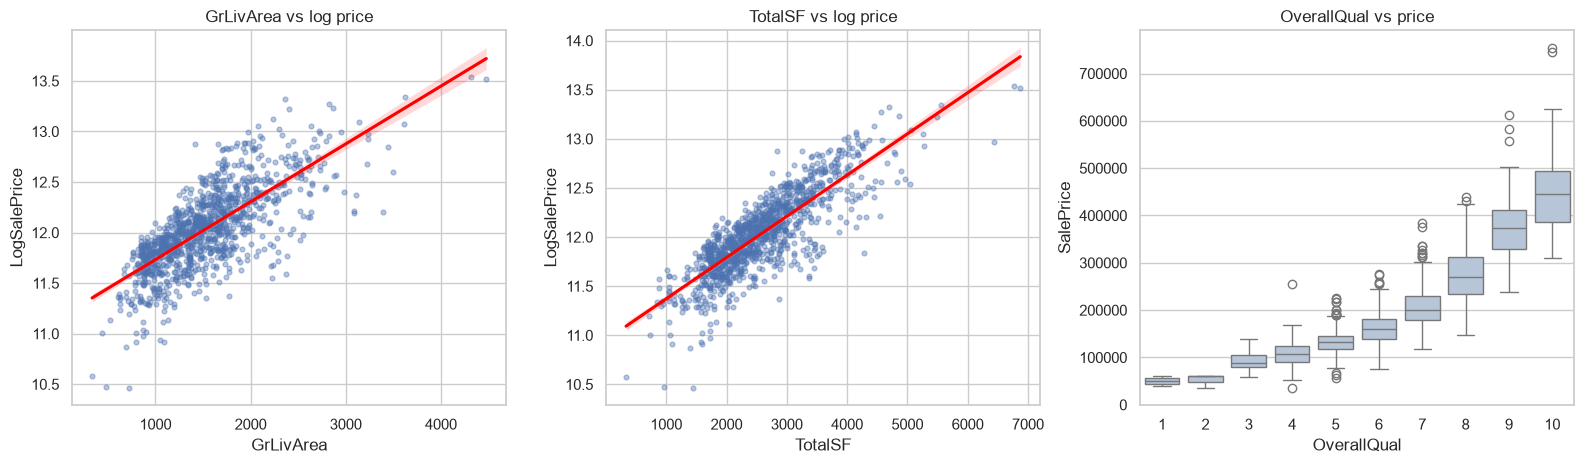

OverallQual,1,2,3,4,5,6,7,8,9,10
count,2.000,3.000,16.000,98.000,310.000,300.000,256.000,132.000,33.000,16.000
median,"50,150.000","60,000.000","89,250.000","108,250.000","133,000.000","159,750.000","199,400.000","270,500.000","374,000.000","445,365.000"


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

sns.regplot(data=eda_df, x="GrLivArea", y="LogSalePrice", scatter_kws={"s": 12, "alpha": 0.4}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("GrLivArea vs log price")

sns.regplot(data=eda_df, x="TotalSF", y="LogSalePrice", scatter_kws={"s": 12, "alpha": 0.4}, line_kws={"color": "red"}, ax=axes[1])
axes[1].set_title("TotalSF vs log price")

sns.boxplot(data=eda_df, x="OverallQual", y="SalePrice", color="lightsteelblue", ax=axes[2])
axes[2].set_title("OverallQual vs price")

plt.tight_layout()
plt.show()

eda_df.groupby("OverallQual")["SalePrice"].agg(["count", "median"]).T

**Observed**
- Both area charts go up in a nearly straight line. The `TotalSF` points sit closer to the red line than the `GrLivArea` points, which matches the correlations (0.831 vs 0.739).
- `OverallQual`: the median price goes up at every level, from 50,150 (level 1) to 445,365 (level 10). The jumps get bigger at the top: 199,400 (7), 270,500 (8), 374,000 (9).
- The boxes also get taller with quality, so expensive houses vary more in price.
- Levels 1, 2 and 10 have very few houses (2, 3 and 16), so those medians are less sure.

**Action**: size and quality both matter a lot, and `TotalSF` is the better size column. The price grows faster than a straight line in dollars, which is another reason to use the log price.


### 3.4. Rating columns vs price

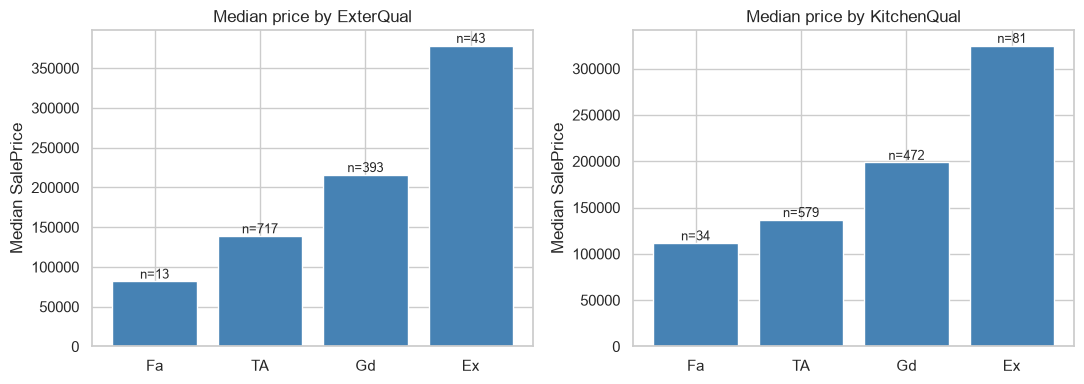

In [ ]:
rating_names = {0: "None", 1: "Po", 2: "Fa", 3: "TA", 4: "Gd", 5: "Ex"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, ["ExterQual", "KitchenQual"]):
    g = eda_df.groupby(c)["SalePrice"].agg(["count", "median"])
    labels = [rating_names[i] for i in g.index]
    ax.bar(labels, g["median"], color="steelblue")
    for x, (n, m) in enumerate(zip(g["count"], g["median"])):
        ax.text(x, m, f"n={n}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"Median price by {c}")
    ax.set_ylabel("Median SalePrice")
plt.tight_layout()
plt.show()

**Observed**: for both `ExterQual` and `KitchenQual`, every step up the rating (Fa, TA, Gd, Ex) gives a higher median price. Most houses sit in `TA` and `Gd`, and `Ex` has only a few houses (see the `n=` labels).

**Action**: turning the letters into 0-5 numbers (1.4) was a good move. The model sees the order directly.


### 3.5. Location

`Neighborhood` is the part of Ames the house is in. The names used below: `NridgHt` = Northridge Heights, `NoRidge` = Northridge, `StoneBr` = Stone Brook, `BrDale` = Briardale, `IDOTRR` = near the Iowa DOT and railroad, `MeadowV` = Meadow Village.


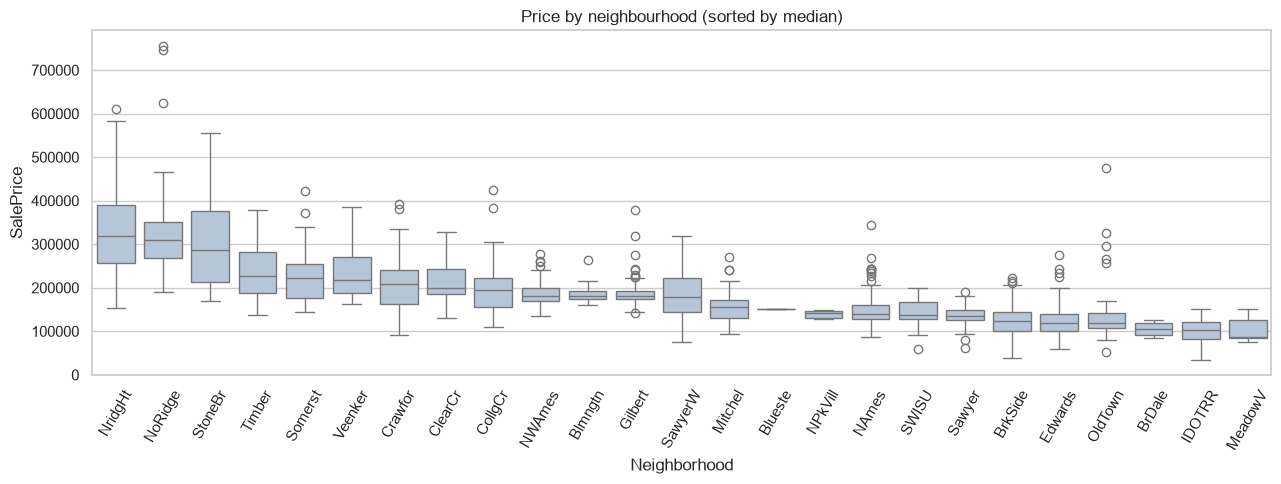

Top 3 and bottom 3 neighbourhoods:


,houses,median_price,median_OverallQual
Neighborhood,,,
NridgHt,63,"318,061.000",8.000
NoRidge,33,"310,000.000",8.000
StoneBr,21,"286,000.000",8.000
BrDale,12,"106,000.000",6.000
IDOTRR,34,"102,888.000",5.000
MeadowV,13,"86,000.000",4.000


Neighbourhoods with fewer than 10 houses in train: 3 of 25


In [ ]:
order = eda_df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).index

plt.figure(figsize=(13, 5))
sns.boxplot(data=eda_df, x="Neighborhood", y="SalePrice", order=order, color="lightsteelblue")
plt.xticks(rotation=60)
plt.title("Price by neighbourhood (sorted by median)")
plt.tight_layout()
plt.show()

nb_table = eda_df.groupby("Neighborhood").agg(houses=("SalePrice", "count"),
                                              median_price=("SalePrice", "median"),
                                              median_OverallQual=("OverallQual", "median")).sort_values("median_price", ascending=False)
print("Top 3 and bottom 3 neighbourhoods:")
display(pd.concat([nb_table.head(3), nb_table.tail(3)]))
print("Neighbourhoods with fewer than 10 houses in train:", int((nb_table["houses"] < 10).sum()), "of", len(nb_table))


**Observed**
- Location has a big effect. The median price in the most expensive area (`NridgHt`, 318,061) is about 3.7 times the cheapest (`MeadowV`, 86,000). Top 3: `NridgHt`, `NoRidge`, `StoneBr`. Bottom 3: `BrDale`, `IDOTRR`, `MeadowV`.
- The expensive areas also have a higher median `OverallQual` than the cheap areas (last column). So part of the price gap is better-built houses, not only the address.
- 3 of the 25 neighbourhoods have fewer than 10 houses.

**Action**: keep `Neighborhood` as a column (it can't show up in the correlation chart because it is text). The rare areas are grouped by the pipeline (2.4).


### 3.6. Sale type and zoning

`SaleCondition`: `Normal` = normal sale, `Partial` = house was not finished when assessed (mostly new homes), `Abnorml` = foreclosure, short sale or trade, `Family` = sold between family, `Alloca` = two linked properties, `AdjLand` = neighbouring land.

`MSZoning`: `RL` = residential low density, `RM` = residential medium density, `RH` = residential high density, `FV` = floating village residential, `C (all)` = commercial.


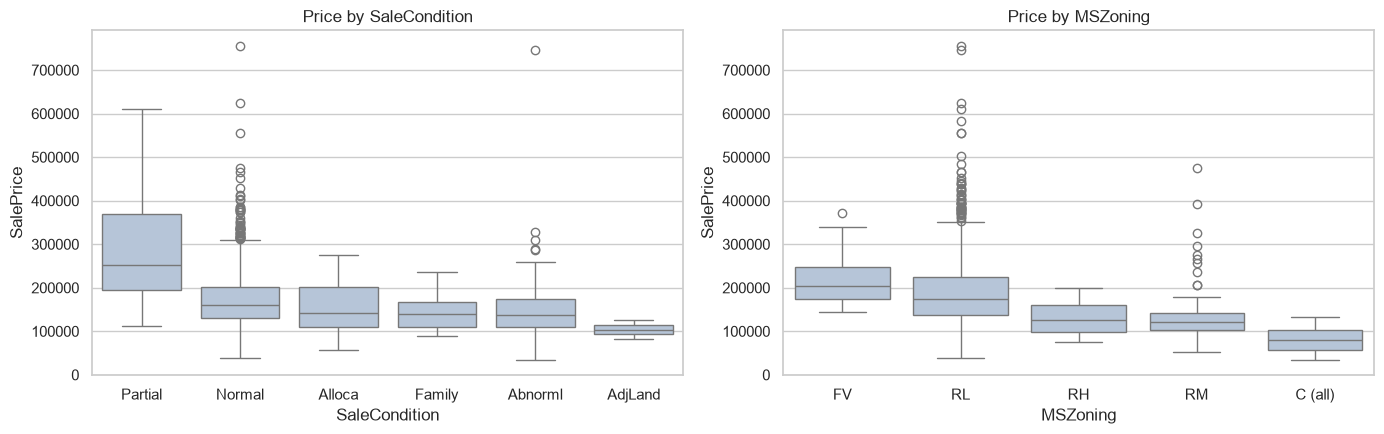

,houses,median_price,median_HouseAge
SaleCondition,,,
Partial,107,"253,293.000",1.000
Normal,946,"159,975.000",38.000
Alloca,9,"142,953.000",39.000
Family,14,"140,000.000",43.000
Abnorml,88,"138,150.000",43.500
AdjLand,2,"104,000.000",60.000


,count,median
MSZoning,,
FV,54,"202,925.000"
RL,923,"173,000.000"
RH,12,"124,950.000"
RM,168,"120,250.000"
C (all),9,"81,000.000"


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ["SaleCondition", "MSZoning"]):
    ordr = eda_df.groupby(col)["SalePrice"].median().sort_values(ascending=False).index
    sns.boxplot(data=eda_df, x=col, y="SalePrice", order=ordr, color="lightsteelblue", ax=ax)
    ax.set_title(f"Price by {col}")
plt.tight_layout()
plt.show()

sale_table = eda_df.groupby("SaleCondition").agg(houses=("SalePrice", "count"),
                                                 median_price=("SalePrice", "median"),
                                                 median_HouseAge=("HouseAge", "median")).sort_values("median_price", ascending=False)
zone_table = eda_df.groupby("MSZoning")["SalePrice"].agg(["count", "median"]).sort_values("median", ascending=False)
display(sale_table)
display(zone_table)

**Observed**
- `Partial` sales are the most expensive: median 253,293 vs 159,975 for `Normal` (about 58% more). The `median_HouseAge` column shows `Partial` houses are very new.
- `Abnorml` sales (foreclosure and similar) are cheaper: 138,150, about 14% below `Normal`.
- Zoning: `FV` 202,925 and `RL` 173,000 are the highest, `RM` 120,250 is lower, and `C (all)` is the lowest at 81,000 (only 9 houses).

**Action**: keep both columns. Part of the `Partial` effect is simply "new house", so expect `SaleCondition` and `HouseAge` to share some of the work.


### 3.7. Age and time of sale

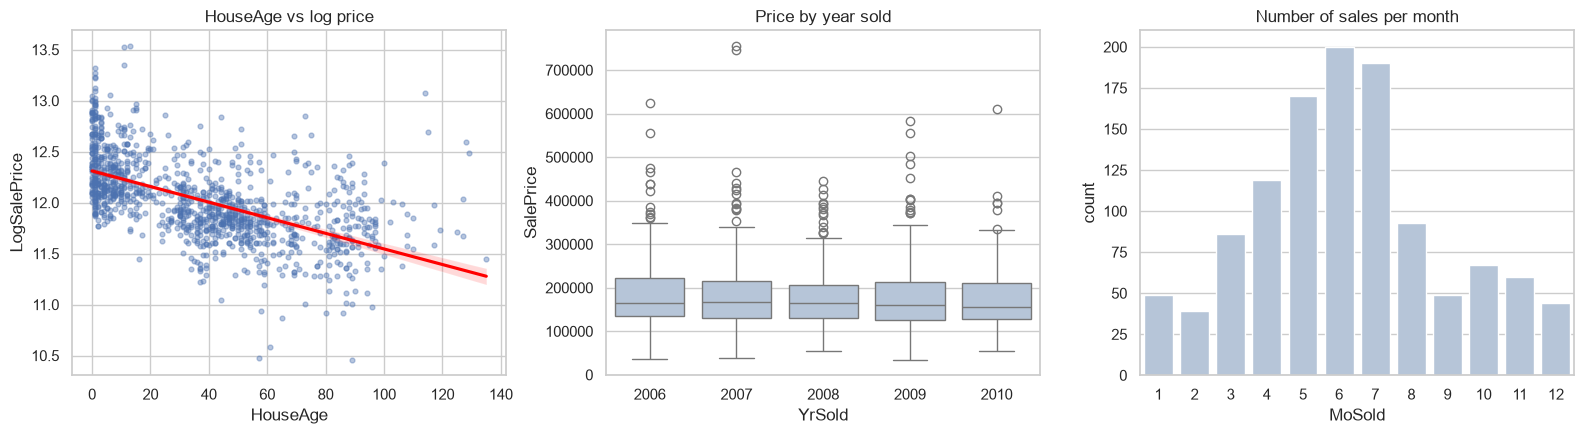

Median price by year sold:
YrSold
2006   164,500.000
2007   168,000.000
2008   165,500.000
2009   160,200.000
2010   154,650.000


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.regplot(data=eda_df, x="HouseAge", y="LogSalePrice", scatter_kws={"s": 12, "alpha": 0.4}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("HouseAge vs log price")

sns.boxplot(data=eda_df, x="YrSold", y="SalePrice", color="lightsteelblue", ax=axes[1])
axes[1].set_title("Price by year sold")

month_order = [str(m) for m in range(1, 13)]
sns.countplot(data=eda_df, x="MoSold", order=month_order, color="lightsteelblue", ax=axes[2])
axes[2].set_title("Number of sales per month")

plt.tight_layout()
plt.show()

print("Median price by year sold:")
print(eda_df.groupby("YrSold")["SalePrice"].median().to_string())

**Observed**
- `HouseAge`: price drops fast for the first ~40 years, then flattens (the points bend, the red straight line only shows the average trend). Brand-new houses (age 0) range from cheap to the most expensive in the data.
- `YrSold`: median price goes 164,500 (2006), 168,000, 165,500, 160,200, 154,650 (2010). That is only about 6% lower from 2006 to 2010, and the boxes overlap almost completely.
- `MoSold`: sales have a clear season. June has the most (about 200), February the fewest (about 40). Month-to-month medians in 1.4 do not follow that pattern.

**Action**
- Keep `HouseAge`: it matters, but the wide spread says quality and size matter more.
- `YrSold` has little effect on price, so it is a weak column. We keep it only because `HouseAge` was built from it.
- Keep `MoSold` as text (a label), as decided in 1.4.

### 3.8. Summary

| # | What we found | Evidence | What we do |
|---|---|---|---|
| 1 | Price has a long tail to the right | skewness 1.97 raw vs 0.23 after log (3.1) | Model `log1p(SalePrice)` |
| 2 | Size and quality drive price | `TotalSF` 0.831, `OverallQual` 0.830, `GrLivArea` 0.739 (3.2, 3.3) | Keep. `TotalSF` is a helpful new column |
| 3 | Rating letters are a real scale | price rises with each step in `ExterQual` and `KitchenQual` (3.4) | Keep them as 0-5 numbers |
| 4 | Location matters a lot | `NridgHt` 318,061 vs `MeadowV` 86,000, about 3.7 times (3.5) | Keep `Neighborhood`, group rare areas |
| 5 | Part of the location gap is quality | expensive areas have higher median `OverallQual` (3.5) | Models may share the effect between the two columns, that's OK |
| 6 | `Partial` sales cost more | 253,293 vs 159,975, about 58% more, and these houses are very new (3.6) | Keep `SaleCondition`, expect overlap with `HouseAge` |
| 7 | Newer houses cost more, with a wide spread | `HouseAge` -0.576 (3.2, 3.7) | Keep `HouseAge` |
| 8 | Year sold barely matters | median only about 6% lower from 2006 to 2010 (3.7) | `YrSold` is weak. Keep `MoSold` as text |
| 9 | Some columns overlap | `GarageCars`/`GarageArea` 0.894, `GrLivArea`/`TotalSF` 0.870 and more (3.2) | Keep for now. Use Ridge/Lasso for linear models |
